# V11 Stratified Group Cross-Validation

This notebook performs leakage-free two-fold cross-validation for V11. Acquisition windows are the indivisible groups. Each fold recomputes its own preprocessing statistics, trains a fresh model, evaluates the fixed 0.65 confidence threshold, and saves independent artifacts. The two out-of-fold results are finally pooled by summing TP, FP, and FN.

## 1. Setup and execution policy

The default configuration runs only fold 0. This makes the long experiment resumable:

1. Run the notebook with the default flags to train fold 0.
2. After fold 0 completes, set `RUN_FOLD_0 = False`, `TRAIN_FOLD_0 = False`, `RUN_FOLD_1 = True`, and leave `TRAIN_FOLD_1 = True`.
3. Run the notebook again to train fold 1 and produce the pooled summary.
4. Once both folds exist, set both training flags to `False`. Saved histories, checkpoints, and metrics can then be reused without retraining.

Running both folds together is possible, but sequential execution is safer on a CPU-only Windows environment and makes failures recoverable.

In [12]:
%matplotlib inline

import getpass
import json
import os
import random
import sys
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from huggingface_hub import HfApi, hf_hub_download
from scipy.optimize import linear_sum_assignment

SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Reload local modules so a previously opened Jupyter kernel cannot use stale code.
import importlib
import modeling as modeling_module
import preprocessing as preprocessing_module
modeling_module = importlib.reload(modeling_module)
preprocessing_module = importlib.reload(preprocessing_module)

from modeling import (
    MetricAlignedPermutationLoss, build_baseline_model,
    person_count_accuracy,
)
from preprocessing import (
    PreprocessingConfig, build_sorted_targets, normalize_per_radar_channel,
    per_radar_channel_moments, transform_phase_ema_temporal,
)

SEED = 42
RUN_FOLD_0 = False
TRAIN_FOLD_0 = False
RUN_FOLD_1 = True
TRAIN_FOLD_1 = True
RECOMPUTE_FOLD_STATISTICS = False

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

ARTIFACT_DIR = SRC_DIR / 'artifacts'
MODEL_DIR = SRC_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print('TensorFlow version:', tf.__version__)
print('Source directory:', SRC_DIR.resolve())

TensorFlow version: 2.21.0
Source directory: C:\Users\213053\OneDrive\Documenti\EEAI\src


## 2. Load and validate the grouped folds

The split artifact was generated from the EDA occupancy map. Both validation folds must be disjoint, their union must contain all 24 windows, and every validation fold must contain at least one window for each occupancy from zero to four people.

In [13]:
GROUP_SPLIT_PATH = ARTIFACT_DIR / 'v11_stratified_group_2fold.json'
if not GROUP_SPLIT_PATH.exists():
    raise FileNotFoundError(
        'Run Section 17 of 04_baseline_model.ipynb to create the grouped split artifact.'
    )
with GROUP_SPLIT_PATH.open(encoding='utf-8') as handle:
    group_split_artifact = json.load(handle)

CV_FOLDS = group_split_artifact['folds']
WINDOWS_BY_OCCUPANCY = {
    0: [22, 23],
    1: [16, 17, 18, 19, 20, 21],
    2: [0, 1, 2, 3, 4],
    3: [12, 13, 14, 15],
    4: [5, 6, 7, 8, 9, 10, 11],
}
assert len(CV_FOLDS) == 2
validation_sets = [set(fold['validation_windows']) for fold in CV_FOLDS]
assert validation_sets[0].isdisjoint(validation_sets[1])
assert validation_sets[0] | validation_sets[1] == set(range(24))

for fold in CV_FOLDS:
    train_set = set(fold['training_windows'])
    validation_set = set(fold['validation_windows'])
    assert train_set.isdisjoint(validation_set)
    assert train_set | validation_set == set(range(24))
    occupancy_counts = {
        occupancy: len(validation_set & set(windows))
        for occupancy, windows in WINDOWS_BY_OCCUPANCY.items()
    }
    assert all(count >= 1 for count in occupancy_counts.values())
    print(
        f'Fold {fold["fold"]}: {len(train_set)} training windows, '
        f'{len(validation_set)} validation windows, occupancy={occupancy_counts}'
    )

Fold 0: 11 training windows, 13 validation windows, occupancy={0: 1, 1: 3, 2: 3, 3: 2, 4: 4}
Fold 1: 13 training windows, 11 validation windows, occupancy={0: 1, 1: 3, 2: 2, 3: 2, 4: 3}


## 3. Authenticate and cache the dataset

The Hugging Face token is read from `HF_TOKEN`; if it is unavailable, the notebook requests it securely. Dataset files are cached by `huggingface_hub`, so repeated runs do not download unchanged windows again. The token is never written to an artifact or notebook output.

In [14]:
HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
print('Authenticated as:', HfApi(token=HF_TOKEN).whoami()['name'])

REPO_ID = 'HAEEAI/multi-person-localization'
window_paths = {
    index: Path(hf_hub_download(
        repo_id=REPO_ID,
        repo_type='dataset',
        filename=f'data/window_{index:06d}.npz',
        token=HF_TOKEN,
    ))
    for index in range(24)
}
print(f'{len(window_paths)} acquisition windows are cached and ready.')

Authenticated as: KetrinMehmeti
24 acquisition windows are cached and ready.


## 4. Fixed V11 preprocessing and model contract

Cross-validation changes only the acquisition split. V11 preprocessing, architecture, physical-distance loss, optimiser, batch size, and fixed confidence threshold remain unchanged. Fold-specific normalisation is mandatory because using statistics computed from validation windows would leak distribution information.

In [15]:
V11_CONFIG = PreprocessingConfig(
    radar_indices=(0, 1, 2, 3, 4, 5),
    antenna_mode='none',
    range_bin_start=0,
    range_bin_stop=120,
    log_compression=True,
    background_mode='ema',
    ema_alpha=0.98,
)
INPUT_SHAPE = (6, 36, 120)
FILTERS = (24, 32, 48)
DENSE_UNITS = 64
DROPOUT_RATE = 0.15
LEARNING_RATE = 5e-4
BATCH_SIZE = 128
CHUNK_SIZE = 256
EPOCHS = 25
FRAMES_PER_WINDOW = 7500
FIXED_CONFIDENCE_THRESHOLD = 0.65
MATCH_DISTANCE_M = 1.0
ROOM_SCALE = np.asarray([4.8, 7.2], dtype=np.float32)

LOSS_CONFIG = {
    'localization_weight': 2.0,
    'confidence_weight': 1.0,
    'huber_delta_m': 1.0,
    'match_distance_m': MATCH_DISTANCE_M,
    'tail_weight': 1.0,
}

screening_model = build_baseline_model(
    input_shape=INPUT_SHAPE,
    filters=FILTERS,
    dense_units=DENSE_UNITS,
    dropout_rate=DROPOUT_RATE,
    preserve_spatial_layout=True,
)
print('V11 parameters:', f'{screening_model.count_params():,}')
print('Estimated INT8 weights:', f'{screening_model.count_params() / 1024:.1f} KiB')
assert screening_model.count_params() == 140_540

V11 parameters: 140,540
Estimated INT8 weights: 137.2 KiB


## 5. Fold-specific preprocessing statistics

EMA and previous-frame states remain continuous across storage chunks and reset only at acquisition boundaries. Statistics are accumulated only from the fold's training windows and cached in a fold-specific JSON file. Existing statistics are accepted only when their recorded training and validation windows exactly match the current fold.

In [16]:
def training_feature_blocks(training_windows):
    for position, window_index in enumerate(training_windows, start=1):
        print(
            f'  statistics window {position:02d}/{len(training_windows):02d}: '
            f'{window_index:06d}'
        )
        ema_state, previous_state = None, None
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            for start in range(0, len(radar), CHUNK_SIZE):
                features, ema_state, previous_state = transform_phase_ema_temporal(
                    radar[start:start + CHUNK_SIZE],
                    V11_CONFIG,
                    ema_state,
                    previous_state,
                )
                yield features


def load_or_compute_fold_statistics(fold):
    fold_index = int(fold['fold'])
    stats_path = ARTIFACT_DIR / f'v11_cv_fold_{fold_index}_normalization.json'
    if stats_path.exists() and not RECOMPUTE_FOLD_STATISTICS:
        with stats_path.open(encoding='utf-8') as handle:
            artifact = json.load(handle)
        assert artifact['training_windows'] == fold['training_windows']
        assert artifact['validation_windows'] == fold['validation_windows']
        mean = np.asarray(artifact['mean'], dtype=np.float32)
        std = np.asarray(artifact['std'], dtype=np.float32)
        print(f'Fold {fold_index}: loaded cached training-only statistics.')
    else:
        print(f'Fold {fold_index}: computing training-only statistics.')
        mean, std, value_count = per_radar_channel_moments(
            training_feature_blocks(fold['training_windows'])
        )
        artifact = {
            'fold': fold_index,
            'representation': 'phase_ema_previous_frame',
            'training_windows': fold['training_windows'],
            'validation_windows': fold['validation_windows'],
            'mean': mean.tolist(),
            'std': std.tolist(),
            'values_per_channel': int(value_count),
        }
        with stats_path.open('w', encoding='utf-8') as handle:
            json.dump(artifact, handle, indent=2)
        print('Saved:', stats_path.resolve())
    assert mean.shape == std.shape == (6, 36)
    assert np.isfinite(mean).all() and np.isfinite(std).all()
    assert np.all(std > 0)
    return mean, std, stats_path

## 6. Causal datasets for one fold

Every window is transformed chronologically before frame-level shuffling. This is essential: shuffling raw frames before EMA and previous-frame construction would destroy temporal causality. Training frames are shuffled only after valid temporal features have been generated.

In [17]:
DATASET_SIGNATURE = (
    tf.TensorSpec(shape=(None,) + INPUT_SHAPE, dtype=tf.float32),
    tf.TensorSpec(shape=(None, 4, 3), dtype=tf.float32),
)


def fold_window_chunk_generator(window_indices, mean, std):
    for window_index in window_indices:
        ema_state, previous_state = None, None
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            people_xy = data['people_xy']
            people_mask = data['people_mask']
            for start in range(0, len(radar), CHUNK_SIZE):
                stop = min(start + CHUNK_SIZE, len(radar))
                features, ema_state, previous_state = transform_phase_ema_temporal(
                    radar[start:stop], V11_CONFIG, ema_state, previous_state
                )
                features = normalize_per_radar_channel(
                    features, mean, std, V11_CONFIG.epsilon
                )
                targets = build_sorted_targets(
                    people_xy[start:stop], people_mask[start:stop]
                )
                yield features, targets


def make_fold_dataset(window_indices, mean, std, training, repeat=False):
    dataset = tf.data.Dataset.from_generator(
        lambda: fold_window_chunk_generator(window_indices, mean, std),
        output_signature=DATASET_SIGNATURE,
    ).unbatch()
    if training:
        dataset = dataset.shuffle(8192, seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if repeat:
        dataset = dataset.repeat()
    return dataset.prefetch(tf.data.AUTOTUNE)

## 7. Official evaluation and common visualisations

The evaluator applies per-frame Hungarian matching and accepts assignments within 1 m. Cross-validation uses the previously frozen 0.65 confidence threshold. No threshold is selected independently on either fold.

In [18]:
def evaluate_hungarian(targets, predictions, confidence_threshold):
    tp = fp = fn = 0
    matched_distances = []
    true_counts, predicted_counts = [], []
    for target, prediction in zip(targets, predictions):
        ground_truth = target[target[:, 0] >= 0.5, 1:] * ROOM_SCALE
        predicted = prediction[prediction[:, 0] >= confidence_threshold, 1:] * ROOM_SCALE
        predicted = np.clip(predicted, [0.0, 0.0], ROOM_SCALE)
        true_counts.append(len(ground_truth))
        predicted_counts.append(len(predicted))
        matches = 0
        if len(ground_truth) and len(predicted):
            distances = np.linalg.norm(
                ground_truth[:, None, :] - predicted[None, :, :], axis=-1
            )
            gt_indices, prediction_indices = linear_sum_assignment(distances)
            assigned = distances[gt_indices, prediction_indices]
            accepted = assigned <= MATCH_DISTANCE_M
            matches = int(accepted.sum())
            matched_distances.extend(assigned[accepted].tolist())
        tp += matches
        fp += len(predicted) - matches
        fn += len(ground_truth) - matches

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    matched_distances = np.asarray(matched_distances, dtype=np.float32)
    true_counts = np.asarray(true_counts)
    predicted_counts = np.asarray(predicted_counts)
    return {
        'threshold': float(confidence_threshold),
        'frames': int(len(targets)),
        'tp': int(tp), 'fp': int(fp), 'fn': int(fn),
        'precision': float(precision), 'recall': float(recall), 'f1': float(f1),
        'matched_mae_m': float(matched_distances.mean()) if len(matched_distances) else None,
        'matched_p90_m': float(np.percentile(matched_distances, 90)) if len(matched_distances) else None,
        'count_mae': float(np.mean(np.abs(true_counts - predicted_counts))),
        'count_accuracy': float(np.mean(true_counts == predicted_counts)),
    }


def plot_convergence(history, fold_index):
    epochs = np.arange(1, len(history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(epochs, history['loss'], label='Training')
    axes[0].plot(epochs, history['val_loss'], label='Validation')
    axes[0].set(title=f'Fold {fold_index} Loss', xlabel='Epoch', ylabel='Loss')
    axes[1].plot(epochs, history['person_count_accuracy'], label='Training')
    axes[1].plot(epochs, history['val_person_count_accuracy'], label='Validation')
    axes[1].set(
        title=f'Fold {fold_index} Count Accuracy',
        xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1.02),
    )
    for axis in axes:
        axis.grid(alpha=0.25)
        axis.legend()
    plt.tight_layout()
    plt.show()


def plot_occupancy_results(occupancy_results, fold_index):
    occupancies = np.arange(5)
    f1_values = [occupancy_results[str(value)]['f1'] for value in occupancies]
    count_values = [occupancy_results[str(value)]['count_accuracy'] for value in occupancies]
    mae_values = [
        occupancy_results[str(value)]['matched_mae_m']
        if occupancy_results[str(value)]['matched_mae_m'] is not None else 0.0
        for value in occupancies
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    axes[0].bar(occupancies, f1_values, color='#3478bf')
    axes[0].set(title=f'Fold {fold_index} F1 by Occupancy', xlabel='People', ylim=(0, 1.02))
    axes[1].bar(occupancies, count_values, color='#55a868')
    axes[1].set(title=f'Fold {fold_index} Count Accuracy', xlabel='People', ylim=(0, 1.02))
    axes[2].bar(occupancies, mae_values, color='#c44e52')
    axes[2].set(title=f'Fold {fold_index} Matched MAE', xlabel='People', ylabel='Metres')
    for axis in axes:
        axis.set_xticks(occupancies)
        axis.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    plt.show()

## 8. Reusable fold experiment

Each call below performs one complete, independent experiment: fold-specific statistics, causal datasets, fresh V11 initialisation, checkpointing, convergence plots, official fixed-threshold evaluation, occupancy diagnostics, and JSON result saving. A completed fold can later be loaded without retraining.

In [19]:
def run_fold_experiment(fold, train_model):
    fold_index = int(fold['fold'])
    mean, std, stats_path = load_or_compute_fold_statistics(fold)
    train_dataset = make_fold_dataset(
        fold['training_windows'], mean, std, training=True, repeat=True
    )
    validation_fit_dataset = make_fold_dataset(
        fold['validation_windows'], mean, std, training=False, repeat=True
    )
    validation_dataset = make_fold_dataset(
        fold['validation_windows'], mean, std, training=False, repeat=False
    )

    sample_features, _ = next(iter(train_dataset))
    print(f'Fold {fold_index} sample shape:', sample_features.shape)
    print(
        f'Fold {fold_index} sample range:',
        float(tf.reduce_min(sample_features)), float(tf.reduce_max(sample_features)),
    )
    assert np.isfinite(sample_features.numpy()).all()

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_baseline_model(
        input_shape=INPUT_SHAPE,
        filters=FILTERS,
        dense_units=DENSE_UNITS,
        dropout_rate=DROPOUT_RATE,
        preserve_spatial_layout=True,
    )
    assert model.count_params() == 140_540
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=MetricAlignedPermutationLoss(**LOSS_CONFIG),
        metrics=[person_count_accuracy],
    )

    model_path = MODEL_DIR / f'baseline_v11_cv_fold_{fold_index}_best.keras'
    history_path = ARTIFACT_DIR / f'baseline_v11_cv_fold_{fold_index}_history.json'
    result_path = ARTIFACT_DIR / f'baseline_v11_cv_fold_{fold_index}_results.json'

    if train_model:
        history_object = model.fit(
            train_dataset,
            validation_data=validation_fit_dataset,
            steps_per_epoch=int(np.ceil(
                len(fold['training_windows']) * FRAMES_PER_WINDOW / BATCH_SIZE
            )),
            validation_steps=int(np.ceil(
                len(fold['validation_windows']) * FRAMES_PER_WINDOW / BATCH_SIZE
            )),
            epochs=EPOCHS,
            callbacks=[
                tf.keras.callbacks.ModelCheckpoint(
                    model_path, monitor='val_loss', save_best_only=True, verbose=1
                ),
                tf.keras.callbacks.ReduceLROnPlateau(
                    monitor='val_loss', factor=0.5, patience=2,
                    min_lr=1e-5, verbose=1,
                ),
                tf.keras.callbacks.EarlyStopping(
                    monitor='val_loss', patience=5,
                    restore_best_weights=True, verbose=1,
                ),
            ],
            verbose=1,
        )
        history = {
            key: [float(value) for value in values]
            for key, values in history_object.history.items()
        }
        with history_path.open('w', encoding='utf-8') as handle:
            json.dump(history, handle, indent=2)
    else:
        if not model_path.exists() or not history_path.exists():
            raise FileNotFoundError(
                f'Fold {fold_index} is not trained. Enable its TRAIN_FOLD flag once.'
            )
        with history_path.open(encoding='utf-8') as handle:
            history = json.load(handle)
        print(f'Fold {fold_index}: training skipped; saved checkpoint and history loaded.')

    plot_convergence(history, fold_index)
    best_model = tf.keras.models.load_model(model_path)
    target_batches, prediction_batches = [], []
    for features, targets in validation_dataset:
        target_batches.append(targets.numpy())
        prediction_batches.append(best_model(features, training=False).numpy())
    targets = np.concatenate(target_batches)
    predictions = np.concatenate(prediction_batches)
    expected_frames = len(fold['validation_windows']) * FRAMES_PER_WINDOW
    assert len(targets) == len(predictions) == expected_frames

    fixed_result = evaluate_hungarian(
        targets, predictions, FIXED_CONFIDENCE_THRESHOLD
    )
    occupancy_results = {}
    for occupancy in range(5):
        frame_mask = targets[..., 0].sum(axis=1).astype(int) == occupancy
        occupancy_results[str(occupancy)] = evaluate_hungarian(
            targets[frame_mask], predictions[frame_mask], FIXED_CONFIDENCE_THRESHOLD
        )
    print('Fixed-threshold fold result:')
    print(json.dumps(fixed_result, indent=2))
    for occupancy, result in occupancy_results.items():
        print(
            f'{occupancy} people | frames={result["frames"]:,} | '
            f'F1={result["f1"]:.4f} | count acc={result["count_accuracy"]:.4f}'
        )
    plot_occupancy_results(occupancy_results, fold_index)

    artifact = {
        'version': 'V11',
        'protocol': 'two-fold occupancy-stratified acquisition-group cross-validation',
        'fold': fold_index,
        'training_windows': fold['training_windows'],
        'validation_windows': fold['validation_windows'],
        'normalization_artifact': stats_path.name,
        'model_artifact': model_path.name,
        'parameters': int(best_model.count_params()),
        'fixed_confidence_threshold': FIXED_CONFIDENCE_THRESHOLD,
        'metrics': fixed_result,
        'occupancy_metrics': occupancy_results,
    }
    with result_path.open('w', encoding='utf-8') as handle:
        json.dump(artifact, handle, indent=2)
    print('Saved:', result_path.resolve())
    return artifact

## 9. Fold 0

Fold 0 is enabled by default. It trains on 11 acquisition windows and validates on the complementary 13 windows. Do not interrupt the kernel between epochs unless necessary; checkpointing preserves the best completed epoch, but Keras training does not resume the optimiser automatically from a partially completed call.

In [20]:
fold_0_result = None
if RUN_FOLD_0:
    fold_0_result = run_fold_experiment(CV_FOLDS[0], TRAIN_FOLD_0)
else:
    print('Fold 0 execution skipped by RUN_FOLD_0=False.')

Fold 0 execution skipped by RUN_FOLD_0=False.


## 10. Fold 1

Fold 1 is disabled on the first run. After fold 0 completes, disable fold 0 and enable this fold in the setup cell. Fold 1 trains on 13 acquisition windows and validates on the complementary 11 windows.

Fold 1: computing training-only statistics.
  statistics window 01/13: 000000
  statistics window 02/13: 000002
  statistics window 03/13: 000003
  statistics window 04/13: 000007
  statistics window 05/13: 000008
  statistics window 06/13: 000009
  statistics window 07/13: 000010
  statistics window 08/13: 000012
  statistics window 09/13: 000014
  statistics window 10/13: 000016
  statistics window 11/13: 000017
  statistics window 12/13: 000019
  statistics window 13/13: 000023
Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v11_cv_fold_1_normalization.json
Fold 1 sample shape: (128, 6, 36, 120)
Fold 1 sample range: -27.891616821289062 12.022420883178711
Epoch 1/25
762/762 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - loss: 1.8000 - person_count_accuracy: 0.5771
Epoch 1: val_loss improved from None to 3.37947, saving model to c:\Users\213053\OneDrive\Documenti\EEAI\src\models\baseline_v11_cv_fold_1_best.keras

Epoch 1: finished saving model to c:\Users\213053\OneDrive\Documenti\

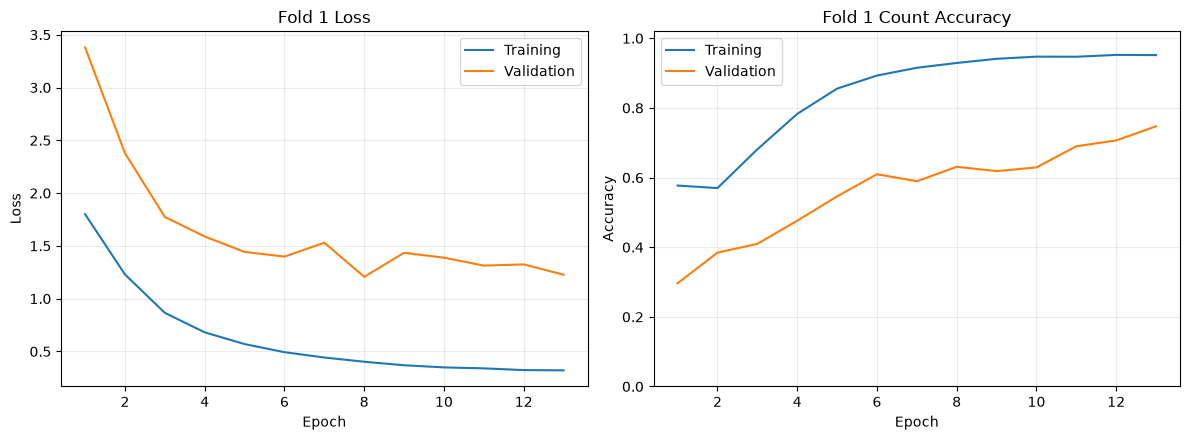

Fixed-threshold fold result:
{
  "threshold": 0.65,
  "frames": 82500,
  "tp": 115233,
  "fp": 41468,
  "fn": 72267,
  "precision": 0.735368631980651,
  "recall": 0.614576,
  "f1": 0.6695680721438927,
  "matched_mae_m": 0.5354859232902527,
  "matched_p90_m": 0.877549946308136,
  "count_mae": 0.4256606060606061,
  "count_accuracy": 0.6103757575757576
}
0 people | frames=7,500 | F1=0.0000 | count acc=0.9999
1 people | frames=22,500 | F1=0.7730 | count acc=0.6410
2 people | frames=15,000 | F1=0.6780 | count acc=0.7855
3 people | frames=15,000 | F1=0.6239 | count acc=0.8129
4 people | frames=22,500 | F1=0.6683 | count acc=0.1981


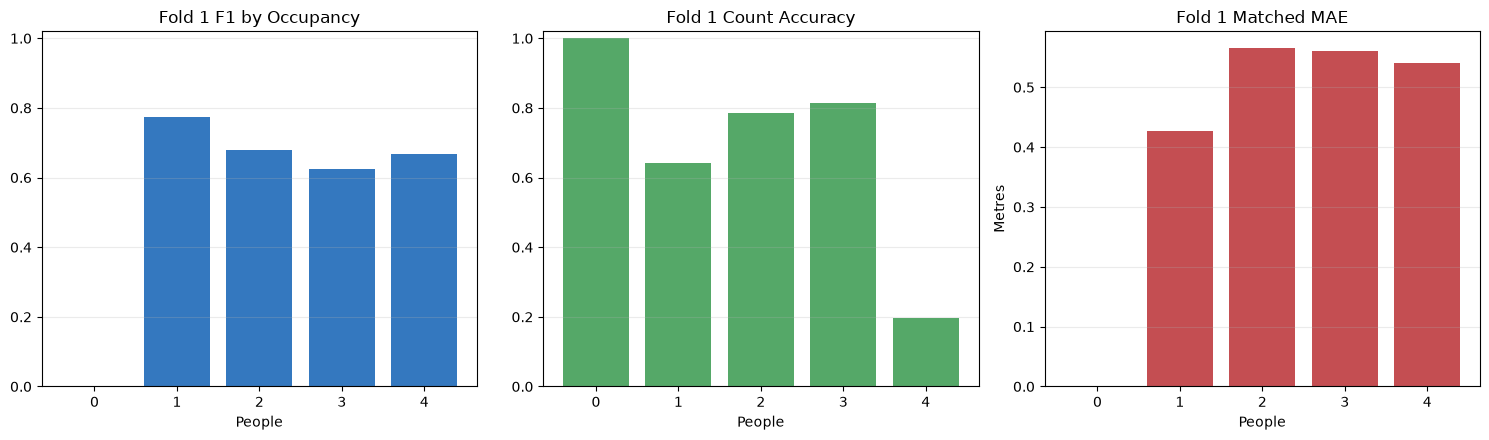

Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\baseline_v11_cv_fold_1_results.json


In [21]:
fold_1_result = None
if RUN_FOLD_1:
    fold_1_result = run_fold_experiment(CV_FOLDS[1], TRAIN_FOLD_1)
else:
    print('Fold 1 execution skipped by RUN_FOLD_1=False.')

## 11. Pooled out-of-fold result

The pooled score is produced only after both fold-result artifacts exist. TP, FP, and FN are summed before computing precision, recall, and F1. This is preferable to averaging the two F1 values because the validation folds contain different numbers of frames and people. Count metrics and matched MAE are weighted by their relevant sample counts.

The fixed 0.65 threshold is used throughout. Reporting the best fold or tuning a separate threshold on each validation fold would overestimate generalisation.

In [22]:
fold_result_paths = [
    ARTIFACT_DIR / f'baseline_v11_cv_fold_{fold_index}_results.json'
    for fold_index in range(2)
]

if all(path.exists() for path in fold_result_paths):
    fold_artifacts = []
    for result_path in fold_result_paths:
        with result_path.open(encoding='utf-8') as handle:
            fold_artifacts.append(json.load(handle))

    fold_metrics = [artifact['metrics'] for artifact in fold_artifacts]
    total_tp = sum(metric['tp'] for metric in fold_metrics)
    total_fp = sum(metric['fp'] for metric in fold_metrics)
    total_fn = sum(metric['fn'] for metric in fold_metrics)
    total_frames = sum(metric['frames'] for metric in fold_metrics)
    pooled_precision = total_tp / (total_tp + total_fp)
    pooled_recall = total_tp / (total_tp + total_fn)
    pooled_f1 = 2 * pooled_precision * pooled_recall / (
        pooled_precision + pooled_recall
    )
    pooled_count_accuracy = sum(
        metric['count_accuracy'] * metric['frames'] for metric in fold_metrics
    ) / total_frames
    pooled_count_mae = sum(
        metric['count_mae'] * metric['frames'] for metric in fold_metrics
    ) / total_frames
    pooled_matched_mae = sum(
        metric['matched_mae_m'] * metric['tp'] for metric in fold_metrics
    ) / total_tp

    pooled_result = {
        'threshold': FIXED_CONFIDENCE_THRESHOLD,
        'frames': int(total_frames),
        'tp': int(total_tp), 'fp': int(total_fp), 'fn': int(total_fn),
        'precision': float(pooled_precision),
        'recall': float(pooled_recall),
        'f1': float(pooled_f1),
        'matched_mae_m': float(pooled_matched_mae),
        'count_mae': float(pooled_count_mae),
        'count_accuracy': float(pooled_count_accuracy),
        'fold_f1': [float(metric['f1']) for metric in fold_metrics],
        'fold_f1_mean': float(np.mean([metric['f1'] for metric in fold_metrics])),
        'fold_f1_range': [
            float(np.min([metric['f1'] for metric in fold_metrics])),
            float(np.max([metric['f1'] for metric in fold_metrics])),
        ],
    }
    print('Fold results:')
    for fold_index, metric in enumerate(fold_metrics):
        print(
            f'  Fold {fold_index}: F1={metric["f1"]:.4f}, '
            f'P={metric["precision"]:.4f}, R={metric["recall"]:.4f}, '
            f'MAE={metric["matched_mae_m"]:.3f} m'
        )
    print('Pooled out-of-fold result:')
    print(json.dumps(pooled_result, indent=2))

    summary = {
        'version': 'V11',
        'protocol': 'two-fold occupancy-stratified acquisition-group cross-validation',
        'split_artifact': GROUP_SPLIT_PATH.name,
        'fixed_confidence_threshold': FIXED_CONFIDENCE_THRESHOLD,
        'fold_results': fold_artifacts,
        'pooled_result': pooled_result,
    }
    summary_path = ARTIFACT_DIR / 'baseline_v11_stratified_group_cv_summary.json'
    with summary_path.open('w', encoding='utf-8') as handle:
        json.dump(summary, handle, indent=2)
    print('Saved:', summary_path.resolve())
else:
    missing = [path.name for path in fold_result_paths if not path.exists()]
    print('Pooled result pending. Missing fold artifacts:', missing)

Fold results:
  Fold 0: F1=0.6992, P=0.6896, R=0.7090, MAE=0.531 m
  Fold 1: F1=0.6696, P=0.7354, R=0.6146, MAE=0.535 m
Pooled out-of-fold result:
{
  "threshold": 0.65,
  "frames": 180000,
  "tp": 280072,
  "fp": 115664,
  "fn": 139928,
  "precision": 0.7077243414801787,
  "recall": 0.6668380952380952,
  "f1": 0.6866731393490051,
  "matched_mae_m": 0.5327614024313425,
  "count_mae": 0.3194222222222222,
  "count_accuracy": 0.6987111111111111,
  "fold_f1": [
    0.6991591292268866,
    0.6695680721438927
  ],
  "fold_f1_mean": 0.6843636006853897,
  "fold_f1_range": [
    0.6695680721438927,
    0.6991591292268866
  ]
}
Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\baseline_v11_stratified_group_cv_summary.json


## 12. Interpretation and final-model policy

Cross-validation measures how strongly V11 depends on acquisition conditions. A pooled F1 close to the original 0.8516 with a narrow fold range supports the representation and metric-aligned loss. A large difference between folds identifies session sensitivity and should be investigated before attempting a larger V12. An honest pooled F1 above 0.90 would be strong evidence only because all acquisition windows remain group-disjoint.

Cross-validation models are evaluation artifacts, not the final submission ensemble. After the architecture, preprocessing, loss, and threshold are frozen, one final V11 model may be trained on all 24 windows to use all available labelled data. Its expected generalisation must be justified by the out-of-fold result, and the final full-INT8 checkpoint must still pass the `<800 KB` model-size limit, `<300 KB` TFLite Micro activation arena, supported-operator check, and successful ESP32-S3 inference.